# Project 01 — Manufacturing Production Analytics

## 1. Business Problem

## 2. Project Objective

## 3. Dataset Description

## 4. Import Libraries

## 5. Load Dataset

## 6. Data Understanding

## 7. Data Cleaning

## 8. Feature Engineering

## 9. Exploratory Data Analysis

### 9.1 Production Trends
### 9.2 Quality Analysis
### 9.3 Product Performance
### 9.4 Manufacturing Correlations
### 9.5 Defect & Rework Analysis

## 10. Business Insights

## 11. Recommendations

## 12. Conclusion


## 1. Business Problem

Manufacturing organizations generate large amounts of production,
quality, cost, and inspection data. However, raw production data alone
does not provide clear insight into operational performance.

This project analyzes manufacturing data from a control-transformer
production environment to identify production trends, quality issues,
product-level performance, and rework patterns.

## 2. Objective

The objective of this project is to use Python-based data analysis to:

- Understand manufacturing production patterns
- Analyze production and rejection trends
- Compare product performance
- Identify quality-related patterns
- Analyze defects and rework
- Generate actionable business insights

## Tools Used

- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## 3 Dataset Description

The dataset contains 3,000 synthetic records representing
control transformers manufactured and inspected during the period
January 2026 to June 2026.

Each row represents one manufactured transformer.

The dataset contains information related to:

- Production
- Product specifications
- Manufacturing time
- Materials and costs
- Quality inspection
- Defects
- Rework

## 4. Import Libraries

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Why these libraries?

- **Pandas** — data loading, cleaning, transformation and analysis
- **Matplotlib** — data visualization
- **Seaborn** — statistical visualizations

## 5. Load Dataset

In [2]:
# Data Loading

df = pd.read_csv("manufacturing_production_data.csv")

## 6. Data Understanding

In [3]:
df.head()


,Date,Transformer_ID,Product_Type,Production_Line,Shift,Operator_ID,Rated_Power_VA,Input_Voltage_V,Output_Voltage_V,Winding_Time_Min,...,Insulation_Resistance_MOhm,No_Load_Current_mA,Voltage_Test_Result,Defect_Type,Inspection_Result,Rework_Required,Rework_Time_Min,Material_Cost_INR,Labor_Cost_INR,Total_Production_Cost_INR
0,2026-01-01,TR-00123,160VA,Line_A,Evening,OP_017,160,230,24,32.0,...,135.4,84.2,Pass,NaN,Pass,No,0.0,1025.51,295.64,1321.15
1,2026-01-01,TR-00438,100VA,Line_A,Night,OP_020,100,230,24,23.9,...,137.8,67.6,Pass,NaN,Pass,No,0.0,811.31,258.02,1069.33
2,2026-01-01,TR-00476,100VA,Line_C,Evening,OP_020,100,230,24,36.8,...,118.6,56.7,Pass,NaN,Pass,No,0.0,847.40,302.10,1149.50
3,2026-01-01,TR-00634,160VA,Line_B,Morning,OP_006,160,230,24,41.8,...,120.3,75.1,Pass,NaN,Pass,No,0.0,1110.11,345.04,1455.15
4,2026-01-01,TR-00663,100VA,Line_A,Morning,OP_009,100,230,24,33.5,...,125.5,69.4,Pass,NaN,Pass,No,0.0,845.46,286.52,1131.98


In [4]:
# How many rows and columns

df.shape


(3000, 24)

In [5]:
# What are the data types

df.dtypes


Date                              str
Transformer_ID                    str
Product_Type                      str
Production_Line                   str
Shift                             str
Operator_ID                       str
Rated_Power_VA                  int64
Input_Voltage_V                 int64
Output_Voltage_V                int64
Winding_Time_Min              float64
Assembly_Time_Min             float64
Core_Weight_Kg                float64
Copper_Weight_Kg              float64
Winding_Temperature_C         float64
Insulation_Resistance_MOhm    float64
No_Load_Current_mA            float64
Voltage_Test_Result               str
Defect_Type                       str
Inspection_Result                 str
Rework_Required                   str
Rework_Time_Min               float64
Material_Cost_INR             float64
Labor_Cost_INR                float64
Total_Production_Cost_INR     float64
dtype: object

In [6]:
# Numerical summary

df.describe().T


,count,mean,std,min,25%,50%,75%,max
Rated_Power_VA,3000.0,163.153333,125.751584,50.00,100.0000,100.000,250.0000,500.00
Input_Voltage_V,3000.0,230.000000,0.000000,230.00,230.0000,230.000,230.0000,230.00
Output_Voltage_V,3000.0,25.216000,12.601519,12.00,12.0000,24.000,24.0000,48.00
Winding_Time_Min,3000.0,36.763400,11.695173,15.70,29.0000,33.800,41.1000,70.00
Assembly_Time_Min,3000.0,49.466800,15.373370,21.10,39.1000,45.750,55.0000,90.00
Core_Weight_Kg,3000.0,2.708750,1.512738,1.06,1.8200,2.080,3.5400,7.11
Copper_Weight_Kg,3000.0,0.952593,0.569228,0.30,0.6000,0.735,1.2425,2.62
Winding_Temperature_C,3000.0,66.105067,9.039206,47.20,60.0000,64.300,69.7000,95.00
Insulation_Resistance_MOhm,3000.0,120.866233,10.938120,79.20,113.7000,121.200,128.5000,150.00
No_Load_Current_mA,3000.0,76.366833,18.639244,40.00,63.4000,73.400,84.8000,147.20


In [7]:
# Missing values

df.isnull().sum()


Date                             0
Transformer_ID                   0
Product_Type                     0
Production_Line                  0
Shift                            0
Operator_ID                      0
Rated_Power_VA                   0
Input_Voltage_V                  0
Output_Voltage_V                 0
Winding_Time_Min                 0
Assembly_Time_Min                0
Core_Weight_Kg                   0
Copper_Weight_Kg                 0
Winding_Temperature_C            0
Insulation_Resistance_MOhm       0
No_Load_Current_mA               0
Voltage_Test_Result              0
Defect_Type                   2858
Inspection_Result                0
Rework_Required                  0
Rework_Time_Min                  0
Material_Cost_INR                0
Labor_Cost_INR                   0
Total_Production_Cost_INR        0
dtype: int64

In [8]:
# Duplicate rows

df.duplicated().sum()


np.int64(0)

In [9]:
df["Transformer_ID"].duplicated().sum()


np.int64(0)

In [10]:
# Unique Values

categorical_columns = [
    "Product_Type",
    "Production_Line",
    "Shift",
    "Operator_ID",
    "Voltage_Test_Result",
    "Defect_Type",
    "Inspection_Result",
    "Rework_Required"
]

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print("Number of unique values:", df[column].nunique())
    print("Unique values:", df[column].unique())


--- Product_Type ---
Number of unique values: 5
Unique values: <StringArray>
['160VA', '100VA', '250VA', '50VA', '500VA']
Length: 5, dtype: str

--- Production_Line ---
Number of unique values: 3
Unique values: <StringArray>
['Line_A', 'Line_C', 'Line_B']
Length: 3, dtype: str

--- Shift ---
Number of unique values: 3
Unique values: <StringArray>
['Evening', 'Night', 'Morning']
Length: 3, dtype: str

--- Operator_ID ---
Number of unique values: 20
Unique values: <StringArray>
['OP_017', 'OP_020', 'OP_006', 'OP_009', 'OP_004', 'OP_013', 'OP_003',
 'OP_015', 'OP_010', 'OP_016', 'OP_007', 'OP_019', 'OP_014', 'OP_008',
 'OP_018', 'OP_001', 'OP_005', 'OP_012', 'OP_002', 'OP_011']
Length: 20, dtype: str

--- Voltage_Test_Result ---
Number of unique values: 2
Unique values: <StringArray>
['Pass', 'Fail']
Length: 2, dtype: str

--- Defect_Type ---
Number of unique values: 5
Unique values: <StringArray>
[nan, 'Insulation', 'Winding', 'Voltage', 'Assembly', 'Overheating']
Length: 6, dtype: str


In [11]:
# Value Counts

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print("Number of Value Counts:", df[column].value_counts())
    print("Percentage of Value Counts:", df[column].value_counts(normalize=True) * 100)


--- Product_Type ---
Number of Value Counts: Product_Type
100VA    920
50VA     664
160VA    661
250VA    476
500VA    279
Name: count, dtype: int64
Percentage of Value Counts: Product_Type
100VA    30.666667
50VA     22.133333
160VA    22.033333
250VA    15.866667
500VA     9.300000
Name: proportion, dtype: float64

--- Production_Line ---
Number of Value Counts: Production_Line
Line_A    1212
Line_B    1062
Line_C     726
Name: count, dtype: int64
Percentage of Value Counts: Production_Line
Line_A    40.4
Line_B    35.4
Line_C    24.2
Name: proportion, dtype: float64

--- Shift ---
Number of Value Counts: Shift
Morning    1349
Evening    1162
Night       489
Name: count, dtype: int64
Percentage of Value Counts: Shift
Morning    44.966667
Evening    38.733333
Night      16.300000
Name: proportion, dtype: float64

--- Operator_ID ---
Number of Value Counts: Operator_ID
OP_015    184
OP_018    166
OP_017    165
OP_008    163
OP_020    160
OP_010    158
OP_004    152
OP_001    152
OP_00

## 7. Data Cleaning

In [12]:
# Data quality and cleaning

missing = df.isnull().sum()

missing = missing[missing > 0]

print(missing)

Defect_Type    2858
dtype: int64


In [13]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage = missing_percentage[missing_percentage > 0]

print(missing_percentage)

Defect_Type    95.266667
dtype: float64


In [14]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Transformer IDs:", df["Transformer_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate Transformer IDs: 0


In [15]:
def_typ = df["Defect_Type"].unique()
print(def_typ)

<StringArray>
[nan, 'Insulation', 'Winding', 'Voltage', 'Assembly', 'Overheating']
Length: 6, dtype: str


In [16]:
def_typ_cnt = df[df["Defect_Type"].isna()].groupby("Product_Type").size()
print(def_typ_cnt)

Product_Type
100VA    914
160VA    647
250VA    456
500VA    181
50VA     660
dtype: int64


In [17]:
df["Defect_Type"] = df["Defect_Type"].fillna("No Defect")
print(df["Defect_Type"].isna().sum())

0


In [18]:
def_typ = df["Defect_Type"].unique()
print(def_typ)

<StringArray>
['No Defect', 'Insulation', 'Winding', 'Voltage', 'Assembly', 'Overheating']
Length: 6, dtype: str


### Checking for Invalid Values

In [19]:
invalid_counts = pd.Series({
    "Negative winding time": (df["Winding_Time_Min"] < 0).sum(),
    "Negative assembly time": (df["Assembly_Time_Min"] < 0).sum(),
    "Non-positive core weight": (df["Core_Weight_Kg"] <= 0).sum(),
    "Non-positive copper weight": (df["Copper_Weight_Kg"] <= 0).sum(),
    "Negative material cost": (df["Material_Cost_INR"] < 0).sum(),
    "Negative labor cost": (df["Labor_Cost_INR"] < 0).sum()
})

print(invalid_counts)

Negative winding time         0
Negative assembly time        0
Non-positive core weight      0
Non-positive copper weight    0
Negative material cost        0
Negative labor cost           0
dtype: int64


IQR method

IQR = Q3 - Q1

Lower limit = Q1 - 1.5 × IQR

Upper limit = Q3 + 1.5 × IQR

In [20]:
Q1 = df["Assembly_Time_Min"].quantile(0.25)

In [21]:
Q3 = df["Assembly_Time_Min"].quantile(0.75)

In [22]:
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR



In [23]:
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 39.1
Q3: 55.0
IQR: 15.899999999999999
Lower limit: 15.250000000000004
Upper limit: 78.85


In [24]:
outliers = df[
    (df["Assembly_Time_Min"] < lower_limit) |
    (df["Assembly_Time_Min"] > upper_limit)
]

print(outliers)

            Date Transformer_ID Product_Type Production_Line    Shift  \
34    2026-01-02       TR-02910        500VA          Line_C    Night   
50    2026-01-03       TR-02675        500VA          Line_C  Morning   
52    2026-01-03       TR-02787        500VA          Line_C  Morning   
55    2026-01-04       TR-00315        500VA          Line_A    Night   
68    2026-01-04       TR-02729        500VA          Line_B  Evening   
...          ...            ...          ...             ...      ...   
2962  2026-06-28       TR-01691        500VA          Line_B  Evening   
2974  2026-06-29       TR-00856        500VA          Line_C  Evening   
2980  2026-06-29       TR-02350        500VA          Line_C    Night   
2986  2026-06-29       TR-02962        500VA          Line_C  Morning   
2989  2026-06-30       TR-00730        500VA          Line_A  Morning   

     Operator_ID  Rated_Power_VA  Input_Voltage_V  Output_Voltage_V  \
34        OP_007             500              230   

In [25]:
print("Number of outliers:", len(outliers))

Number of outliers: 276


In [26]:
outliers.groupby("Product_Type").size().sort_values(ascending=False)

Product_Type
500VA    276
dtype: int64

In [27]:
outliers.groupby("Product_Type")["Assembly_Time_Min"].agg(
    ["count", "mean", "min", "max"]
).sort_values("count", ascending=False)

,count,mean,min,max
Product_Type,,,,
500VA,276,88.363043,79.6,90.0


### Outlier Investigation

The IQR method identified 276 observations as statistical outliers in
Assembly_Time_Min.

Further investigation showed that all of these observations belonged to
the 500VA product category, with assembly times between approximately
79.6 and 90 minutes.

These observations appear to represent legitimate differences in
manufacturing requirements for the larger 500VA transformer rather than
data-entry errors.

Therefore, the observations were retained.

In [28]:
# Final Data quality Check

print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Transformer IDs:", df["Transformer_ID"].duplicated().sum())

Missing values: 0
Duplicate rows: 0
Duplicate Transformer IDs: 0


## 8. Feature Engineering

### 8.1 Date-Based Features


In [29]:
date_type = df["Date"].dtype
print(date_type)

str


In [30]:
# Convert into Date Time

df["Date"] = pd.to_datetime(df["Date"])

In [31]:
converted_date_type =df["Date"].dtype
print(converted_date_type)

datetime64[us]


In [32]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Day_of_Week"] = df["Date"].dt.day_name()

In [33]:
df[["Date", "Year", "Month", "Month_Name", "Day_of_Week"]].head()

,Date,Year,Month,Month_Name,Day_of_Week
0,2026-01-01,2026,1,January,Thursday
1,2026-01-01,2026,1,January,Thursday
2,2026-01-01,2026,1,January,Thursday
3,2026-01-01,2026,1,January,Thursday
4,2026-01-01,2026,1,January,Thursday


### 8.2 Manufacturing Time Features


In [34]:
df["Total_Manufacturing_Time_Min"] = (
    df["Winding_Time_Min"] + df["Assembly_Time_Min"]
)

In [35]:
df[
    [
        "Winding_Time_Min",
        "Assembly_Time_Min",
        "Total_Manufacturing_Time_Min"
    ]
].head()

,Winding_Time_Min,Assembly_Time_Min,Total_Manufacturing_Time_Min
0,32.0,45.8,77.8
1,23.9,44.0,67.9
2,36.8,42.7,79.5
3,41.8,49.0,90.8
4,33.5,41.9,75.4


In [36]:
df["Week"] = df["Date"].dt.isocalendar().week

### 8.3 Feature Engineering Summary

Feature engineering was performed to create additional variables
that support time-based and manufacturing-process analysis.

The following features were created:

- Year
- Month
- Month_Name
- Day_of_Week
- Week
- Total_Manufacturing_Time_Min

The engineered features will be used in the exploratory data analysis
to investigate production trends, product performance, and
manufacturing efficiency.

### Section 9

## 9. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand patterns,
relationships, and variations within the manufacturing data.

The analysis focuses on production trends, quality performance,
product-level performance, manufacturing characteristics, and
defects and rework.

### 9.1 Production Trends

Production trends are analyzed to understand how manufacturing output varies over time.

#### 9.1.1 Monthly Production

In [37]:
monthly_production = (
    df.groupby(["Month"])
      .size()
      .reset_index(name="Production")
      .sort_values("Month")
)

monthly_production

,Month,Production
0,1,514
1,2,468
2,3,482
3,4,500
4,5,541
5,6,495


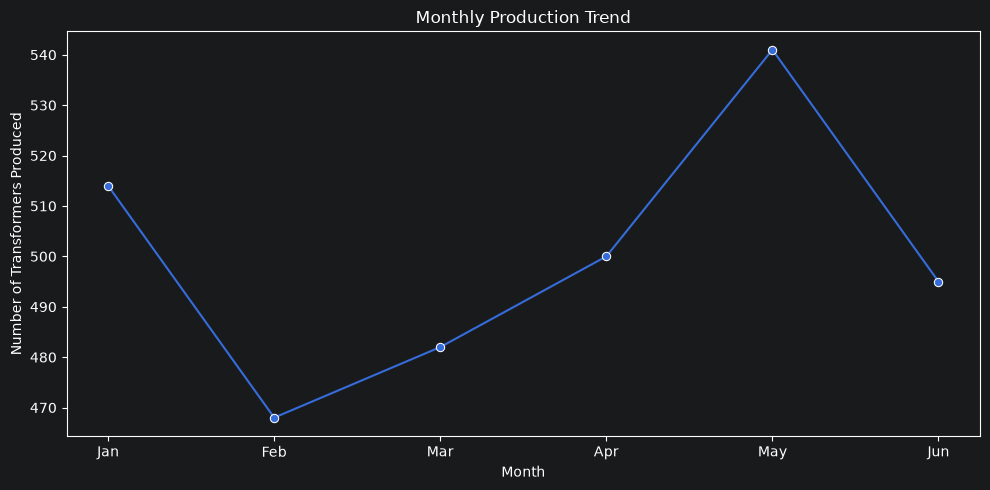

In [38]:

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_production,
    x="Month",
    y="Production",
    marker="o"
)

plt.title("Monthly Production Trend")
plt.xlabel("Month")
plt.ylabel("Number of Transformers Produced")
plt.xticks(range(1,7),["Jan", "Feb", "Mar", "Apr", "May", "Jun"])
plt.tight_layout()
plt.show()

**Observation:**

May recorded the highest production volume, while February recorded
the lowest production volume.



#### 9.1.2 Monthly Rejection Rate

In [39]:

total_production = df.groupby(["Month"]).size()
print(total_production)


Month
1    514
2    468
3    482
4    500
5    541
6    495
dtype: int64


In [40]:
rejected_units = (
    df[df["Inspection_Result"] == "Fail"]
    .groupby(["Month"])
    .size()
)

print(rejected_units)

Month
1    22
2    26
3    22
4    19
5    21
6    32
dtype: int64


In [41]:
rejection_rate = (rejected_units / total_production) * 100

print(rejection_rate)

Month
1    4.280156
2    5.555556
3    4.564315
4    3.800000
5    3.881701
6    6.464646
dtype: float64


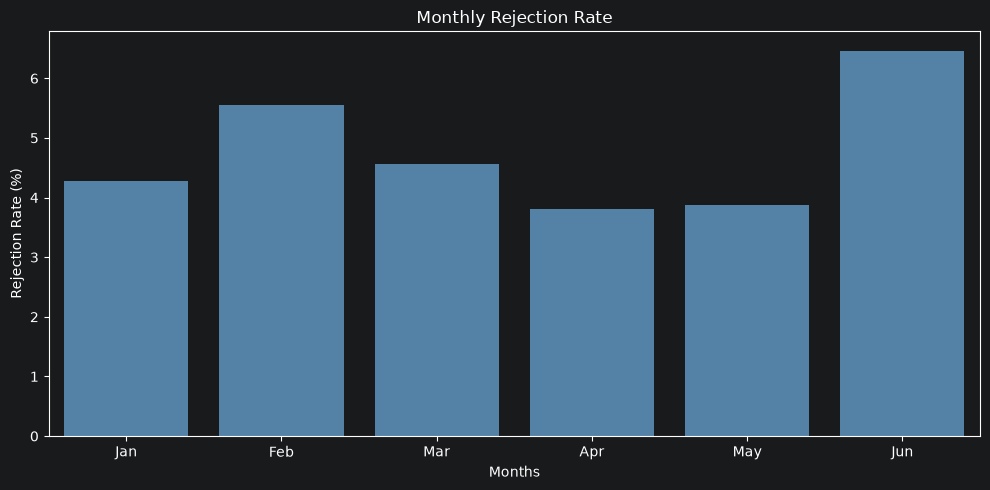

In [42]:
plt.figure(figsize=(10, 5))

sns.barplot(

    x=rejection_rate.index,
    y=rejection_rate.values,
    color="steelblue",
    errorbar=None

)

plt.title("Monthly Rejection Rate")
plt.xlabel("Months")
plt.ylabel("Rejection Rate (%)")
plt.xticks(range(6),["Jan", "Feb", "Mar", "Apr", "May", "Jun"])
plt.tight_layout()
plt.show()

**Observation:**

Monthly production ranged from 468 transformers in February to 541 in May. The monthly rejection rate was lowest in April, at approximately 3.80%, and highest in June, at approximately 6.46%.

The monthly rejection rate did not follow the same pattern as production volume during this period. Further investigation is needed to determine which products, production lines, shifts, or defect categories contributed to the monthly variation.

### 9.2 Quality Analysis

Quality analysis examines the relationship between manufacturing process measurements and final inspection results. The analysis focuses on winding temperature, no-load current, and insulation resistance to identify patterns associated with inspection failures.

#### 9.2.1 Quality Measurements by Inspection Result

In [43]:
quality_by_result = df.groupby("Inspection_Result")[
    [
        "Winding_Temperature_C",
        "No_Load_Current_mA",
        "Insulation_Resistance_MOhm"
    ]
].mean()

print(quality_by_result)

                   Winding_Temperature_C  No_Load_Current_mA  \
Inspection_Result                                              
Fail                           82.506338          109.080282   
Pass                           65.290168           74.741463   

                   Insulation_Resistance_MOhm  
Inspection_Result                              
Fail                               108.988732  
Pass                               121.456368  


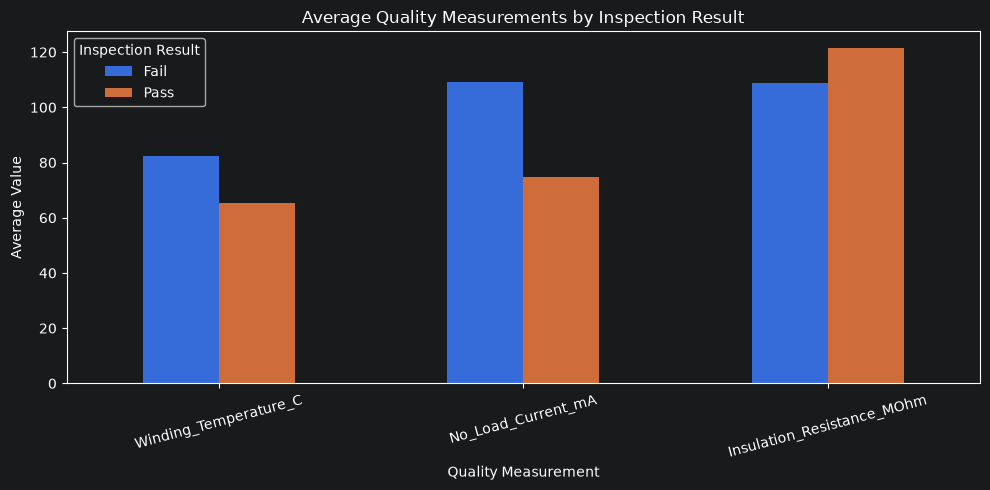

In [44]:
quality_by_result.T.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Quality Measurements by Inspection Result")
plt.xlabel("Quality Measurement")
plt.ylabel("Average Value")
plt.xticks(rotation=15)
plt.legend(title="Inspection Result")
plt.tight_layout()
plt.show()

**Observation:**

Failed transformers had higher average winding temperatures and no-load currents than passed transformers. They also had lower average insulation resistance.

These differences suggest that the three measurements may be associated with inspection outcomes. Further investigation is needed to determine whether the relationships are consistent across product types and other manufacturing conditions.

#### 9.2.2 Winding Temperature vs No-Load Current

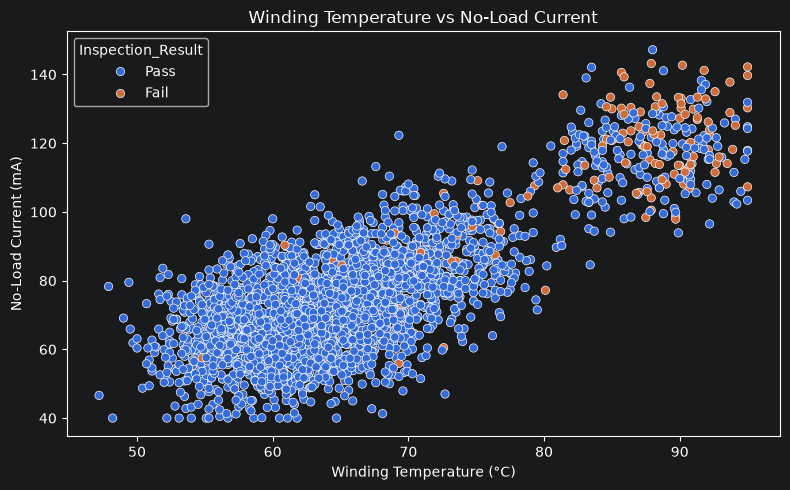

In [45]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Winding_Temperature_C",
    y="No_Load_Current_mA",
    hue="Inspection_Result"
)

plt.title("Winding Temperature vs No-Load Current")
plt.xlabel("Winding Temperature (°C)")
plt.ylabel("No-Load Current (mA)")
plt.tight_layout()
plt.show()

**Observation:**

Winding temperature and no-load current show a strong positive correlation in the dataset. Transformers with higher winding temperatures generally tend to have higher no-load current values.

This relationship is an association and does not establish causation. Additional analysis would be needed to understand how product specifications and manufacturing conditions influence both measurements.

### 9.3 Product Performance

Product performance is analyzed to compare production volume, inspection rejection rates, and manufacturing time across different transformer ratings. This analysis helps identify differences in production demand, quality outcomes, and processing requirements between product types.

#### 9.3.1 Production Volume by Product Type

In [46]:
production_by_product = df["Product_Type"].value_counts()

print(production_by_product)

Product_Type
100VA    920
50VA     664
160VA    661
250VA    476
500VA    279
Name: count, dtype: int64


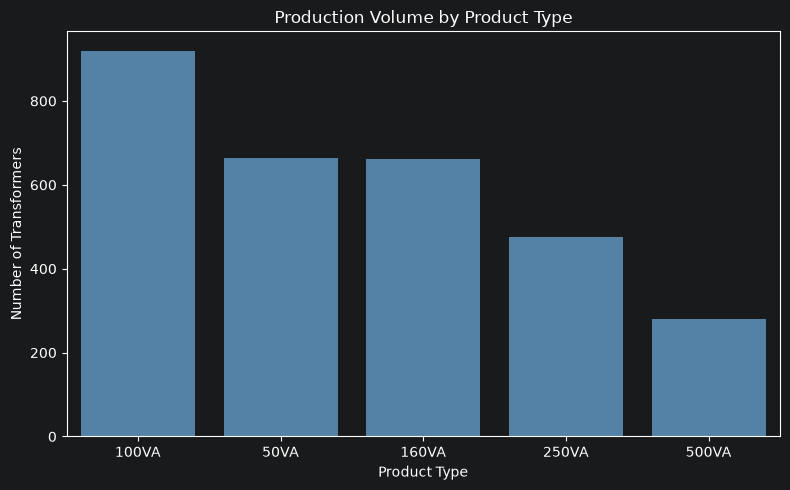

In [47]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=production_by_product.index,
    y=production_by_product.values,
    color="steelblue",
    errorbar=None
)

plt.title("Production Volume by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Number of Transformers")
plt.tight_layout()
plt.show()

**Observation:**

The 100VA transformer was the most frequently produced product, while the 500VA transformer had the lowest production volume. Production volume varied across product types, indicating differences in the product mix during the period.

#### 9.3.2 Rejection Rate by Product Type

In [48]:
total_by_product = df.groupby("Product_Type").size()

rejected_by_product = (
    df[df["Inspection_Result"] == "Fail"]
    .groupby("Product_Type")
    .size()
)

rejection_by_product = (
    rejected_by_product / total_by_product
) * 100

print(rejection_by_product.sort_values(ascending=False))

Product_Type
500VA    35.125448
250VA     4.201681
160VA     2.118003
100VA     0.652174
50VA      0.602410
dtype: float64


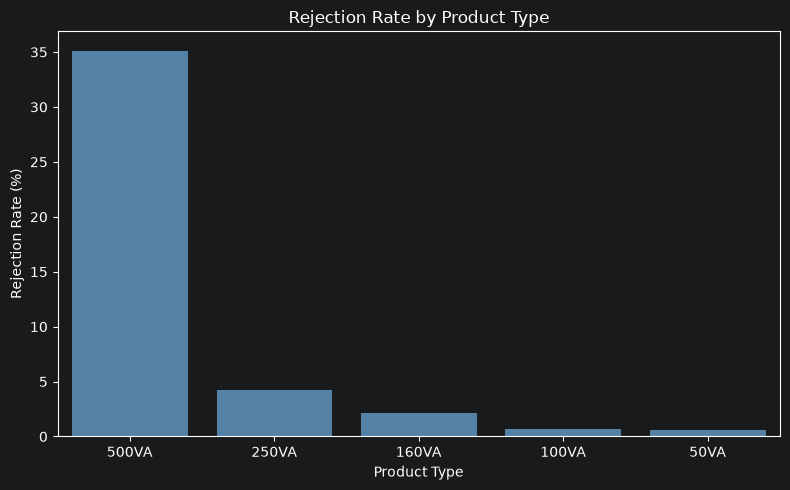

In [49]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=rejection_by_product.sort_values(ascending=False).index,
    y=rejection_by_product.sort_values(ascending=False).values,
    color="steelblue",
    errorbar=None
)

plt.title("Rejection Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Rejection Rate (%)")
plt.tight_layout()
plt.show()

**Observation:**

The 500VA product category recorded a substantially higher rejection rate than the other product types. This makes it a priority for further investigation into defects, manufacturing conditions, and inspection results.

The difference identifies an area for investigation but does not, by itself, explain why the rejection rate is higher.

#### 9.3.3 Average Manufacturing Time by Product Type

In [50]:
manufacturing_time = (
    df.groupby("Product_Type")["Total_Manufacturing_Time_Min"]
    .mean()
    .sort_values(ascending=False)
)

print(manufacturing_time)

Product_Type
500VA    154.960932
250VA    104.164916
160VA     85.560514
100VA     73.683696
50VA      62.544428
Name: Total_Manufacturing_Time_Min, dtype: float64


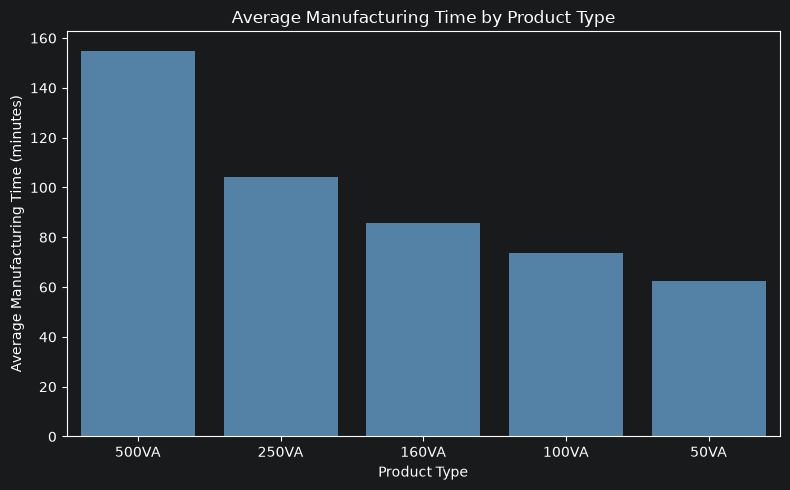

In [51]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=manufacturing_time.index,
    y=manufacturing_time.values,
    color="steelblue",
    errorbar=None
)

plt.title("Average Manufacturing Time by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Average Manufacturing Time (minutes)")
plt.tight_layout()
plt.show()

**Observation:**

Average manufacturing time differs across product types. These differences may reflect variations in winding and assembly requirements. The results can help identify which product categories require more processing time.

### 9.4 Manufacturing Correlations

Manufacturing correlations analysis examines relationships between production parameters, manufacturing time, manufacturing costs, and quality measurements. The objective is to identify patterns and associations that may help guide further investigation into manufacturing performance.

#### 9.4.1 Correlation Between Numerical Variables

In [52]:
numerical_df = df.select_dtypes(include="number")

numerical_df = numerical_df.drop(
    columns=["Year", "Month", "Week"],
    errors="ignore"
)

numerical_df = numerical_df.loc[
    :, numerical_df.nunique() > 1
]

correlation_matrix = numerical_df.corr()

correlation_matrix

,Rated_Power_VA,Output_Voltage_V,Winding_Time_Min,Assembly_Time_Min,Core_Weight_Kg,Copper_Weight_Kg,Winding_Temperature_C,Insulation_Resistance_MOhm,No_Load_Current_mA,Rework_Time_Min,Material_Cost_INR,Labor_Cost_INR,Total_Production_Cost_INR,Total_Manufacturing_Time_Min
Rated_Power_VA,1.000000,-0.016106,0.953583,0.949479,0.997811,0.996358,0.895504,-0.496578,0.832676,0.359564,0.995998,0.956052,0.995911,0.974283
Output_Voltage_V,-0.016106,1.000000,-0.017389,-0.019417,-0.013952,-0.015116,-0.014776,0.000045,0.000158,-0.012592,-0.013866,-0.019916,-0.014963,-0.018990
Winding_Time_Min,0.953583,-0.017389,1.000000,0.904805,0.952046,0.950765,0.869081,-0.489453,0.791646,0.345797,0.950086,0.948010,0.955996,0.968837
Assembly_Time_Min,0.949479,-0.019417,0.904805,1.000000,0.947224,0.946128,0.845595,-0.465739,0.791427,0.336223,0.946137,0.957692,0.954288,0.982085
Core_Weight_Kg,0.997811,-0.013952,0.952046,0.947224,1.000000,0.994021,0.894448,-0.496987,0.831239,0.359164,0.993687,0.954175,0.993656,0.972291
Copper_Weight_Kg,0.996358,-0.015116,0.950765,0.946128,0.994021,1.000000,0.891860,-0.497816,0.829058,0.358997,0.996113,0.953057,0.995509,0.971087
Winding_Temperature_C,0.895504,-0.014776,0.869081,0.845595,0.894448,0.891860,1.000000,-0.562938,0.781023,0.340927,0.890905,0.864069,0.892307,0.876461
Insulation_Resistance_MOhm,-0.496578,0.000045,-0.489453,-0.465739,-0.496987,-0.497816,-0.562938,1.000000,-0.441102,-0.212882,-0.494549,-0.485952,-0.496375,-0.487509
No_Load_Current_mA,0.832676,0.000158,0.791646,0.791427,0.831239,0.829058,0.781023,-0.441102,1.000000,0.342627,0.827921,0.805485,0.829640,0.810685
Rework_Time_Min,0.359564,-0.012592,0.345797,0.336223,0.359164,0.358997,0.340927,-0.212882,0.342627,1.000000,0.358776,0.542039,0.391625,0.348600


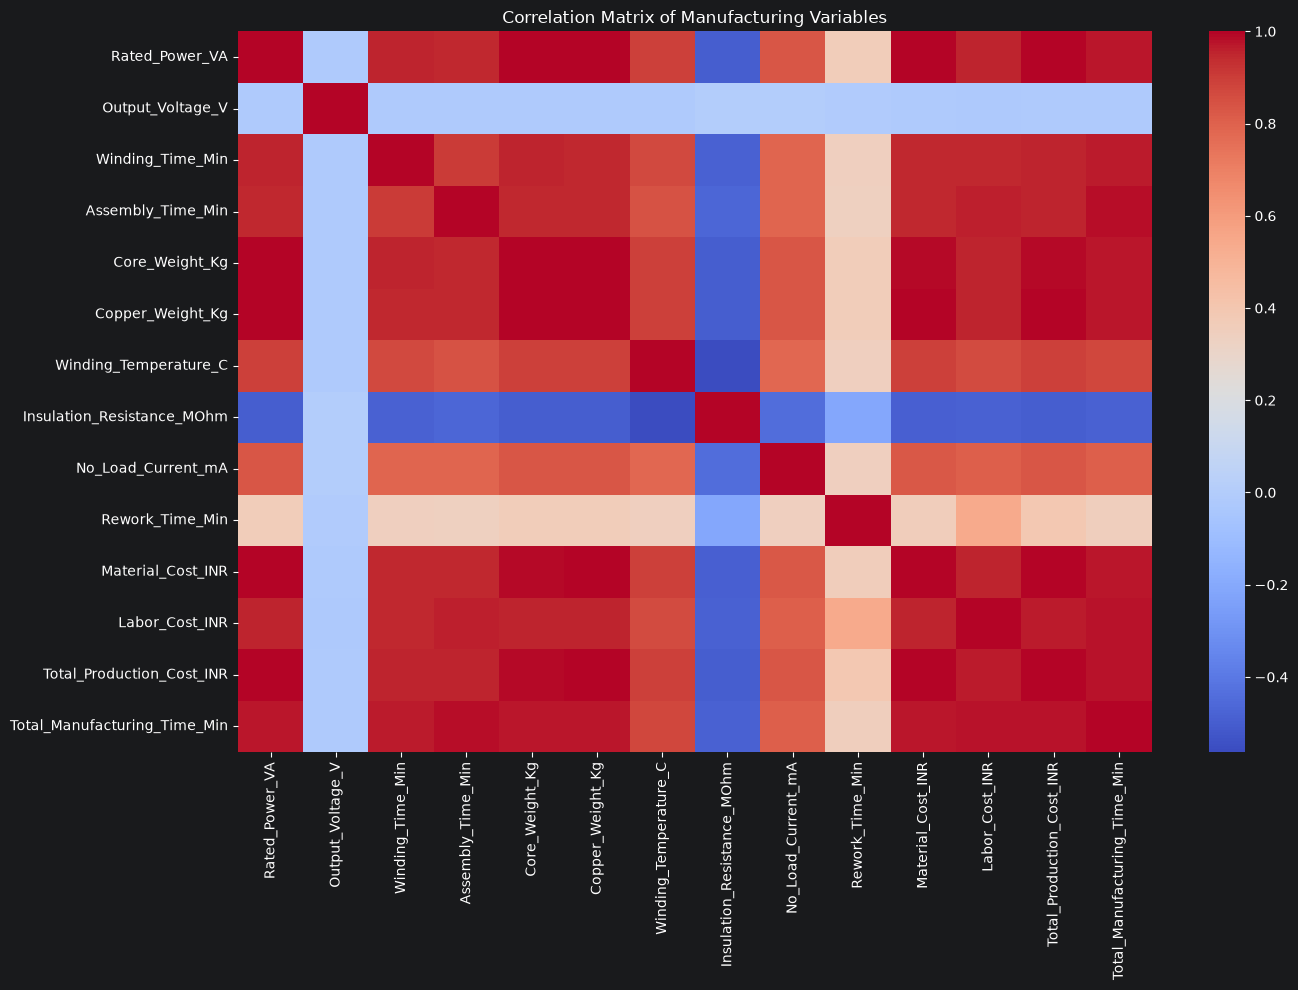

In [53]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=False,
    cmap="coolwarm"
)

plt.title("Correlation Matrix of Manufacturing Variables")
plt.tight_layout()
plt.show()

**Observation:**

The correlation matrix shows several strong relationships between manufacturing variables. Rated power is strongly associated with winding time and assembly time, while material cost is strongly associated with total production cost. Winding temperature also shows a positive association with no-load current.

These relationships identify patterns in the dataset, but correlation does not establish causation. Some strong correlations may also arise because total production cost incorporates material and labor costs.

#### 9.4.2 Distribution of Total Manufacturing Time

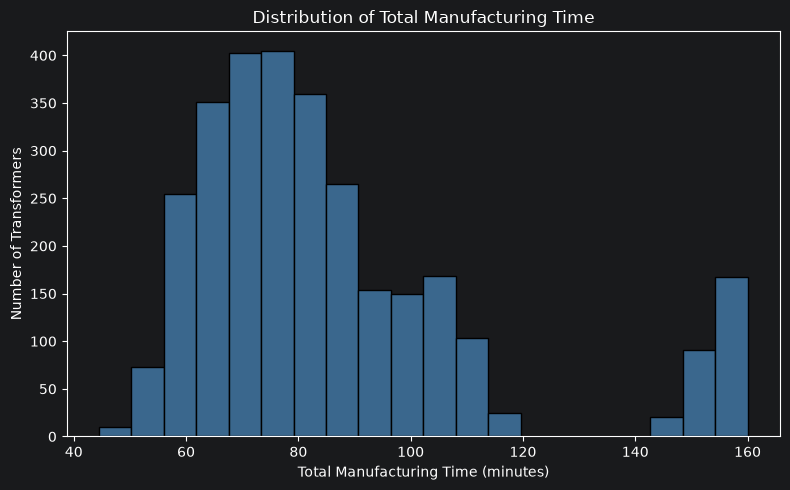

In [54]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Total_Manufacturing_Time_Min",
    color="steelblue",
    bins=20
)

plt.title("Distribution of Total Manufacturing Time")
plt.xlabel("Total Manufacturing Time (minutes)")
plt.ylabel("Number of Transformers")
plt.tight_layout()
plt.show()

**Observation:**

The distribution shows how total manufacturing time varies across the dataset. Differences in processing requirements between product types may contribute to the observed variation.

### 9.5 Defect & Rework Analysis

Defect and rework analysis examines the types of defects recorded during transformer inspection and the rework required to address them. The objective is to identify frequent defects and understand which defect categories have a higher rework burden.

#### 9.5.1 Defect Frequency and Rework Count

In [55]:

common_defects = (
    df.loc[df["Defect_Type"] != "No Defect", "Defect_Type"]
    .value_counts()
)

print(common_defects)

Defect_Type
Voltage        44
Winding        43
Insulation     29
Overheating    15
Assembly       11
Name: count, dtype: int64


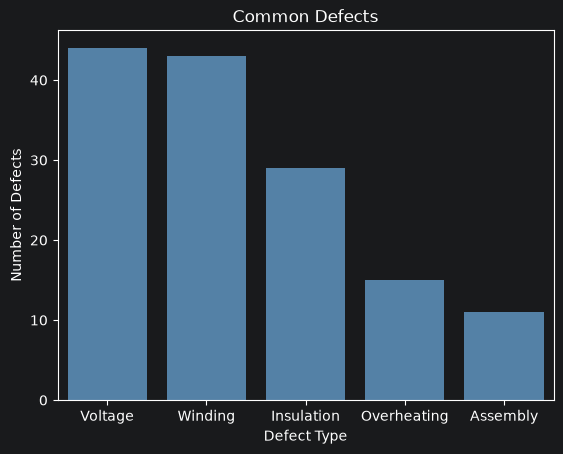

In [56]:
sns.barplot( x=common_defects.index, y = common_defects.values, color="steelblue",)

plt.title("Common Defects")
plt.xlabel("Defect Type")
plt.ylabel("Number of Defects")

plt.show()

In [57]:
most_rework = (
    df[df["Rework_Required"] == "Yes"]
    .groupby("Defect_Type")
    .size()
    .sort_values(ascending=False)
)

print(most_rework)

Defect_Type
Voltage        40
Winding        36
Insulation     21
Overheating    12
Assembly       10
dtype: int64


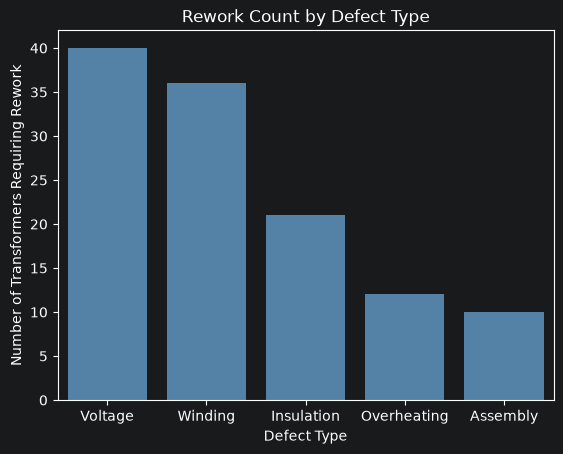

In [58]:
sns.barplot( x=most_rework.index, y = most_rework.values, color="steelblue",)

plt.title("Rework Count by Defect Type")
plt.xlabel("Defect Type")
plt.ylabel("Number of Transformers Requiring Rework")

plt.show()

**Observation**

We can see that voltage and winding defects generated the most rework. This is also related to the high number of defects recorded in these categories.

#### 9.5.2 Rework Rate by Defect Type

In [59]:
defect_totals = (
    df[df["Defect_Type"] != "No Defect"]
    .groupby("Defect_Type")
    .size()
)

In [60]:
rework_totals = (
    df[df["Rework_Required"] == "Yes"]
    .groupby("Defect_Type")
    .size()
)

rework_rate = (rework_totals / defect_totals) * 100

print(rework_rate.sort_values(ascending=False))

Defect_Type
Assembly       90.909091
Voltage        90.909091
Winding        83.720930
Overheating    80.000000
Insulation     72.413793
dtype: float64


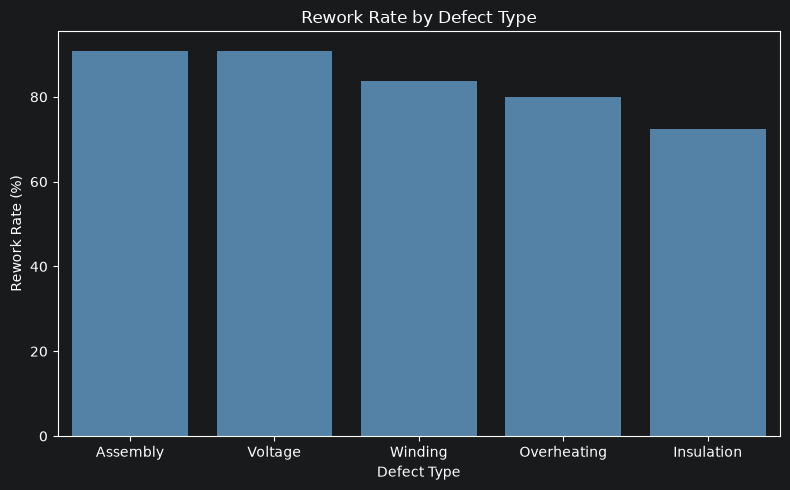

In [61]:
rework_rate = rework_rate.sort_values(ascending=False)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=rework_rate.index,
    y=rework_rate.values,
    color="steelblue",
    errorbar=None
)

plt.title("Rework Rate by Defect Type")
plt.xlabel("Defect Type")
plt.ylabel("Rework Rate (%)")
plt.tight_layout()
plt.show()

**Observation:**

Rework rates vary across defect categories. Assembly and voltage defects each had a rework rate of approximately 90.91%, followed by winding defects at 83.72%, overheating at 80.00%, and insulation defects at 72.41%.

These rates should be considered alongside defect frequency when prioritizing quality improvement efforts.

## 10. Business Insights

The exploratory data analysis revealed several patterns in production volume, inspection quality, product performance, manufacturing measurements, and rework. The following insights summarize the most important findings and their potential operational significance.

### 10.1 Key Findings

**1. Production volume varied across Months.**

We saw production was higher in month of January, April and May compared to other months. We also saw that monthly rejection rates did not follow the same pattern as production volume. We also saw the monthly rejection rate was lowest in April, at approximately 3.80%, and highest in June, at approximately 6.46%.

**2.Manufacturing measurements showed meaningful relationships.**

Winding temperature and no-load current had a strong positive correlation of approximately 0.78. Failed transformers also showed higher average winding temperatures and no-load currents, alongside lower average insulation resistance, than passed transformers. These patterns may help guide further investigation, but they do not establish causation.

**3. Product Performance**

The 100VA transformer was the most frequently produced product, while the 500VA transformer had the lowest production volume. The 500VA product category recorded a substantially higher rejection rate than the other product types.

**4. Correlations between transformers parameters**

&#x20;Rated power is strongly associated with winding time and assembly time, while material cost is strongly associated with total production cost. Winding temperature also shows a positive association with no-load current.

**5. Defect and rework patterns identify potential improvement areas.**

Voltage and winding defects were the most frequently recorded defect categories, with 44 and 43 cases respectively. Rework rates also differed across defect categories. Considering defect frequency alongside rework rate can help prioritize further quality investigations.


### 10.2 Data Limitations

The dataset represents a simulated manufacturing environment. Although it supports demonstration of data cleaning, exploratory analysis, visualization, and business interpretation, the findings should not be treated as verified conclusions about a real manufacturing operation. The observed relationships and rejection patterns would need to be validated using actual production and inspection data before operational decisions were made.

## 11. Recommendations

Based on the findings from the exploratory data analysis, the following recommendations are proposed to improve manufacturing quality, investigate rejection patterns, and support data-driven operational decisions.

### 11.1 Recommended Actions

**1. Investigate the increase in June's rejection rate.**

Review June's inspection records by product type, production line, shift, and defect category. Compare the results with April, which had the lowest monthly rejection rate, to identify patterns that warrant further investigation.

**2. Investigate the high rejection rate for 500VA transformers.**

Review winding, assembly, temperature, insulation resistance, and inspection records for 500VA transformers. Compare these measurements with those of passed units and other product categories to identify potential areas for improvement.

**3. Prioritize frequent defects and rework.**

Review the causes of voltage and winding defects because they are the most frequently recorded categories in the dataset. Also examine defect-specific rework rates so that improvement efforts consider both how often defects occur and how often they require rework.

**4. Monitor manufacturing measurements and quality indicators.**

Track winding temperature, no-load current, insulation resistance, and inspection results together. Establish appropriate operating limits using product specifications and validated manufacturing data, and investigate unusual patterns rather than assuming that correlation alone identifies the cause.


### 11.2 Implementation Considerations

These recommendations are proposed actions based on the patterns observed in the dataset. They have not been validated through production trials. Before implementation in a real manufacturing environment, the findings should be checked against actual production records, engineering specifications, inspection procedures, and process requirements.

## 12. Conclusion

This project analyzed manufacturing production and quality data from a simulated control-transformer manufacturing environment using Python.

The analysis covered data understanding, missing-value treatment, duplicate checks, numerical validation, feature engineering, exploratory data analysis, and business interpretation. Pandas was used for data manipulation and calculations, while Matplotlib and Seaborn were used to visualize production trends, quality measurements, product performance, correlations, and defect and rework patterns.

The analysis identified several areas for further investigation, including the high rejection rate observed for 500VA transformers, variations in monthly rejection rates, and the frequency of voltage and winding defects. Relationships between winding temperature and no-load current were also observed.

The project demonstrates a structured approach to transforming raw manufacturing data into meaningful findings and practical recommendations. The results could help guide further investigation in a real manufacturing environment, although they must first be validated against actual production records and engineering requirements.

Overall, this project strengthened practical skills in Python-based data analysis, data cleaning,
visualization, statistical interpretation, and communicating findings in a business context.
